In [ ]:
!pip install scikit-posthocs

# =====================================================
# Friedman Test + Nemenyi Post-hoc Analysis
# =====================================================


import os
import pandas as pd
import numpy as np
from google.colab import drive
from scipy.stats import friedmanchisquare
import scikit_posthocs as sp

# =====================================================

# =====================================================
drive.mount('/content/drive')

# =====================================================

# =====================================================
excel_path = ("/content/drive/MyDrive/results/paper/All_models_metrics_summary.xlsx")

df_metrics = pd.read_excel(excel_path)

# =====================================================

# =====================================================
metrics_main = ["mae_scaled", "rmse_scaled", "mse_scaled","mase"]
metric_crps = "crps"
all_metrics = metrics_main + [metric_crps]

metric_display_name = {
    "mae_scaled": "MAE",
    "rmse_scaled": "RMSE",
    "mse_scaled": "MSE",
    "mase": "MASE",
    "crps": "CRPS"
}


all_models = ["TimesFM", "Timer", "Moirai", "Lag_Llama", "Chronos","AutoETS","SNaive","AutoARIMA"]

crps_models = [
    "Chronos",
    "Moirai",
    "Lag_Llama"
]

# =====================================================
#
# =====================================================
output_dir = ("/content/drive/MyDrive/results/paper/statistical_tests")

os.makedirs(output_dir, exist_ok=True)

# =====================================================
# 
# =====================================================
required_columns = [
    "model",
    "dataset_id",
    "mae_scaled",
    "rmse_scaled",
    "mse_scaled",
    "crps"
]

missing_columns = [
    col for col in required_columns
    if col not in df_metrics.columns
]

if missing_columns:
    raise ValueError(
        "These columns are missing from the Excel file: "
        + str(missing_columns)
    )

# =====================================================
# 
# =====================================================
friedman_results = []
nemenyi_results = []
rank_results = []
nemenyi_matrix_results = []

# =====================================================
# 
# =====================================================
for metric in all_metrics:

    print("\n")
    print("=" * 100)
    print(f"METRIC: {metric_display_name[metric]}")
    print("=" * 100)

    # -------------------------------------------------
    # 
    # -------------------------------------------------
    if metric == metric_crps:
        models = crps_models.copy()
    else:
        models = all_models.copy()

    # -------------------------------------------------
    # 
    # -------------------------------------------------
    df_use = df_metrics[
        df_metrics["model"].isin(models)
    ].copy()


    wide_df = df_use.pivot(
        index="dataset_id",
        columns="model",
        values=metric
    )


    wide_df = wide_df[
        models
    ].dropna(
        how="any"
    )

  
    n_datasets = len(wide_df)
    n_models = len(models)

    print(f"Number of models: {n_models}")
    print(f"Number of complete datasets: {n_datasets}")
    print(f"Models: {', '.join(models)}")


    if n_datasets < 3:
        print(
            "⚠️ Not enough complete datasets for Friedman test."
        )
        continue


    model_values = [
        wide_df[model].values
        for model in models
    ]

    friedman_stat, friedman_p = friedmanchisquare(
        *model_values
    )


    print("\nFriedman Test:")
    print(f"Statistic = {friedman_stat:.4f}")
    print(f"p-value   = {friedman_p:.12e}")

    if friedman_p < 0.05:
        significance = "Significant"
        print("Result: SIGNIFICANT (p < 0.05)")
    else:
        significance = "Not significant"
        print("Result: NOT SIGNIFICANT (p >= 0.05)")


    friedman_results.append({
        "Metric": metric_display_name[metric],
        "Metric_Code": metric,
        "N_Datasets": n_datasets,
        "N_Models": n_models,
        "Models": ", ".join(models),
        "Friedman_Statistic": friedman_stat,
        "Friedman_p": friedman_p,
        "Significance": significance
    })


    rank_df = wide_df.rank(
        axis=1,
        method="average",
        ascending=True
    )


    mean_ranks = rank_df.mean(axis=0)

    print("\nMean Ranks:")

    for model in models:
        print(
            f"{model:12s}: "
            f"{mean_ranks[model]:.3f}"
        )


    for model in models:

        rank_results.append({
            "Metric": metric_display_name[metric],
            "Metric_Code": metric,
            "Model": model,
            "N_Datasets": n_datasets,
            "Mean_Rank": mean_ranks[model]
        })


    if friedman_p < 0.05:

        print("\n")
        print("Running Nemenyi post-hoc test...")


        nemenyi_matrix = sp.posthoc_nemenyi_friedman(
            wide_df
        )


        nemenyi_matrix.index.name = "Model"
        nemenyi_matrix.columns.name = "Model"


        print("\nNemenyi pairwise p-values:")
        print(
            nemenyi_matrix.round(4)
        )


        nemenyi_matrix_save = nemenyi_matrix.copy()

        nemenyi_matrix_save.insert(
            0,
            "Model",
            nemenyi_matrix_save.index
        )

        nemenyi_matrix_save.insert(
            0,
            "Metric",
            metric_display_name[metric]
        )

        nemenyi_matrix_results.append(
            nemenyi_matrix_save.reset_index(
                drop=True
            )
        )


        for i, model1 in enumerate(models):

            for j, model2 in enumerate(models):

                if j <= i:
                    continue

                p_value = nemenyi_matrix.loc[
                    model1,
                    model2
                ]

                nemenyi_results.append({
                    "Metric": metric_display_name[metric],
                    "Metric_Code": metric,
                    "Model_1": model1,
                    "Model_2": model2,
                    "Mean_Rank_1": mean_ranks[model1],
                    "Mean_Rank_2": mean_ranks[model2],
                    "Nemenyi_p": p_value,
                    "Significant_p<0.05": (
                        "Yes"
                        if p_value < 0.05
                        else "No"
                    )
                })

    else:

        print(
            "\nFriedman test was not significant."
        )

        print(
            "Nemenyi post-hoc was NOT performed."
        )


friedman_df = pd.DataFrame(
    friedman_results
)

rank_df_results = pd.DataFrame(
    rank_results
)

nemenyi_df = pd.DataFrame(
    nemenyi_results
)


if nemenyi_matrix_results:

    nemenyi_matrix_df = pd.concat(
        nemenyi_matrix_results,
        ignore_index=True
    )

else:

    nemenyi_matrix_df = pd.DataFrame()


if not rank_df_results.empty:

    rank_df_results = rank_df_results.sort_values(
        ["Metric", "Mean_Rank"],
        ascending=[True, True]
    )


print("\n")
print("=" * 100)
print("FRIEDMAN TEST RESULTS")
print("=" * 100)

if not friedman_df.empty:

    print(
        friedman_df.to_string(
            index=False,
            float_format=lambda x: f" {x:.12e}"
        )
    )


print("\n")
print("=" * 100)
print("MEAN RANKS")
print("=" * 100)

if not rank_df_results.empty:

    print(
        rank_df_results.to_string(
            index=False,
            float_format=lambda x: f" {x:.4f}"
        )
    )


print("\n")
print("=" * 100)
print("NEMENYI POST-HOC RESULTS")
print("=" * 100)

if not nemenyi_df.empty:

    print(
        nemenyi_df.to_string(
            index=False,
            float_format=lambda x: f" {x:.6f}"
        )
    )

else:

    print(
        "No Nemenyi comparisons were required."
    )


print("\n")
print("=" * 100)
print("NEMENYI PAIRWISE P-VALUES")
print("=" * 100)

if not nemenyi_matrix_df.empty:

    print(
        nemenyi_matrix_df.to_string(
            index=False,
            float_format=lambda x: f" {x:.6f}"
        )
    )

else:

    print(
        "No Nemenyi pairwise matrices were generated."
    )


output_excel = (
    output_dir
    + "/Friedman_Nemenyi_results.xlsx"
)

with pd.ExcelWriter(
    output_excel,
    engine="openpyxl"
) as writer:

    # Friedman
    friedman_df.to_excel(
        writer,
        sheet_name="Friedman",
        index=False
    )

    # Mean ranks
    rank_df_results.to_excel(
        writer,
        sheet_name="Mean_Ranks",
        index=False
    )

    # Nemenyi
    nemenyi_df.to_excel(
        writer,
        sheet_name="Nemenyi",
        index=False
    )

    # Nemenyi Matrix
    nemenyi_matrix_df.to_excel(
        writer,
        sheet_name="Nemenyi_Matrix",
        index=False
    )


print("\n")
print("=" * 100)
print("✅ ANALYSIS COMPLETED")
print("=" * 100)

print("\nResults saved to:")
print(output_excel)

print("\nExcel sheets:")
print("1. Friedman")
print("2. Mean_Ranks")
print("3. Nemenyi")
print("4. Nemenyi_Matrix")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


METRIC: MAE
Number of models: 8
Number of complete datasets: 26
Models: TimesFM, Timer, Moirai, Lag_Llama, Chronos, AutoETS, SNaive, AutoARIMA

Friedman Test:
Statistic = 51.2213
p-value   = 8.310989833721e-09
Result: SIGNIFICANT (p < 0.05)

Mean Ranks:
TimesFM     : 3.577
Timer       : 3.750
Moirai      : 4.442
Lag_Llama   : 7.038
Chronos     : 3.192
AutoETS     : 4.154
SNaive      : 5.808
AutoARIMA   : 4.038


Running Nemenyi post-hoc test...

Nemenyi pairwise p-values:
Model      TimesFM   Timer  Moirai  Lag_Llama  Chronos  AutoETS  SNaive  \
Model                                                                     
TimesFM     1.0000  1.0000  0.9087     0.0000   0.9992   0.9902  0.0229   
Timer       1.0000  1.0000  0.9717     0.0000   0.9920   0.9990  0.0503   
Moirai      0.9087  0.9717  1.0000     0.0033   0.5926   0.9999  0.4751   
Lag_Llama   0.000

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


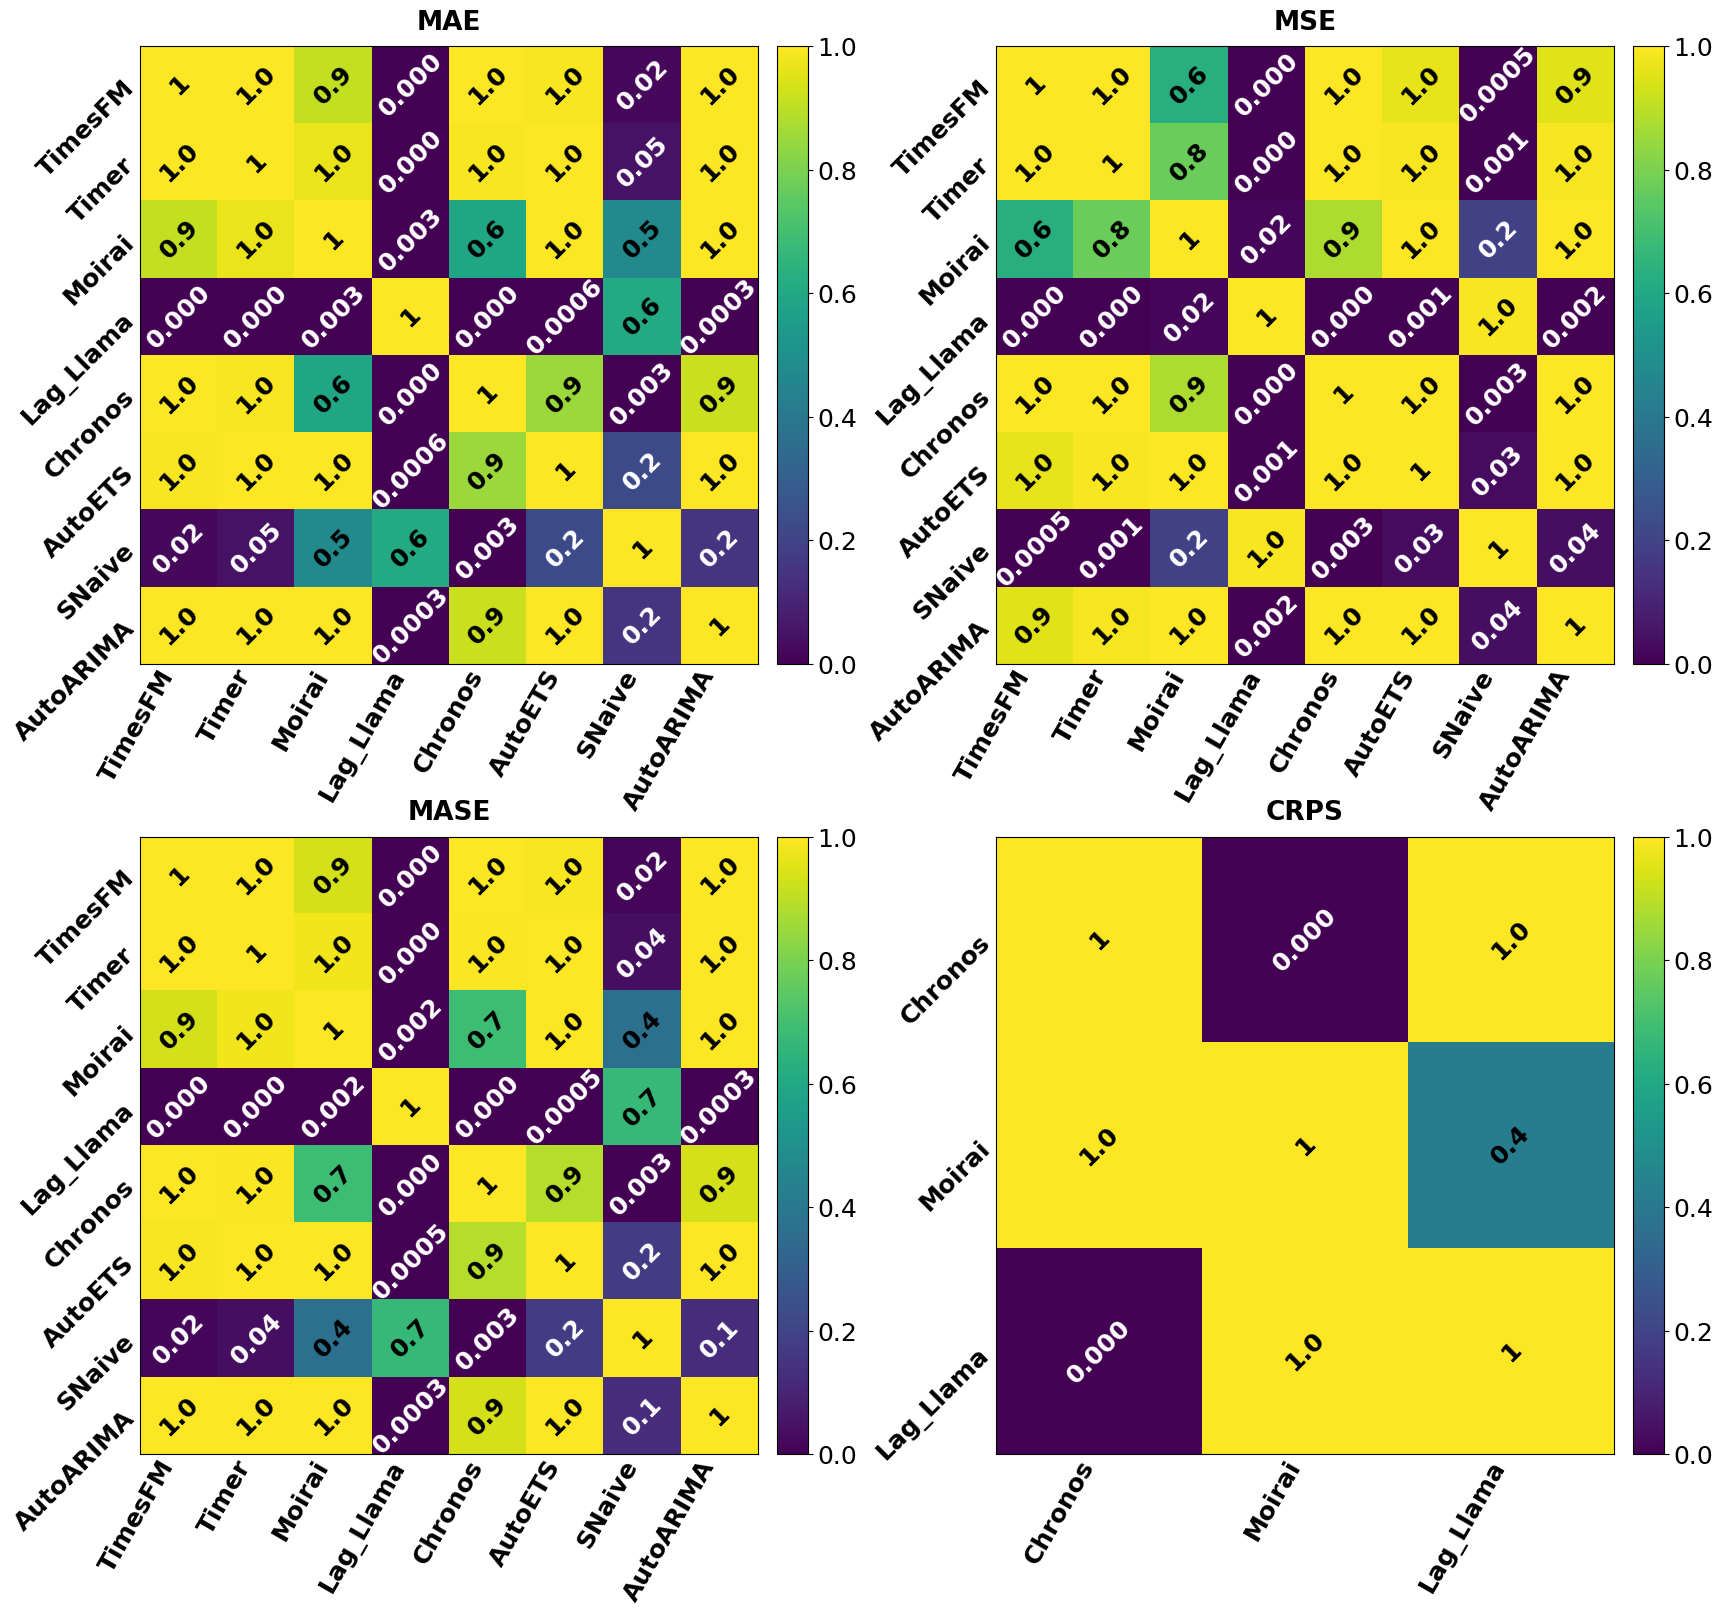


✅ چهار Heatmap در یک شکل 2 × 2 ساخته شد.

مسیر فایل:
/content/drive/MyDrive/results/paper/statistical_tests/nemenyi_heatmaps/Nemenyi_heatmaps_2x2.pdf


In [5]:
# @title
# =====================================================
# Nemenyi Pairwise p-value Heatmaps
# چهار متریک در یک شکل 2 × 2
# =====================================================

# =====================================================
# 0) کتابخانه‌ها
# =====================================================
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive

# =====================================================
# 1) اتصال به Google Drive
# =====================================================
drive.mount("/content/drive")

# =====================================================
# 2) مسیر فایل Excel
# =====================================================
excel_path = (
    "/content/drive/MyDrive/results/paper/statistical_tests/"
    "Friedman_Nemenyi_results.xlsx"
)

# =====================================================
# 3) خواندن ماتریس Nemenyi
# =====================================================
nemenyi_df = pd.read_excel(
    excel_path,
    sheet_name="Nemenyi_Matrix"
)

# =====================================================
# 4) تنظیمات
# =====================================================
metrics = [
    "MAE",
    "MSE",
    "MASE",
    "CRPS"
]

output_dir = (
    "/content/drive/MyDrive/results/paper/statistical_tests/"
    "nemenyi_heatmaps"
)

os.makedirs(
    output_dir,
    exist_ok=True
)

# =====================================================
# 5) مسیر خروجی
# =====================================================
output_pdf = (
    output_dir
    + "/Nemenyi_heatmaps_2x2.pdf"
)

# =====================================================
# 6) ایجاد شکل 2 × 2
# =====================================================
fig, axes = plt.subplots(
    nrows=2,
    ncols=2,
    figsize=(18, 16)
)

# تبدیل به آرایه یک‌بعدی
axes = axes.flatten()

# =====================================================
# 7) رسم هر چهار متریک
# =====================================================
for idx, metric in enumerate(metrics):

    ax = axes[idx]

    # -------------------------------------------------
    # انتخاب متریک
    # -------------------------------------------------
    metric_df = nemenyi_df[
        nemenyi_df["Metric"] == metric
    ].copy()

    if metric_df.empty:

        ax.axis("off")

        continue

    # -------------------------------------------------
    # استخراج مدل‌ها
    # -------------------------------------------------
    model_columns = [
        col
        for col in metric_df.columns
        if col not in ["Metric", "Model"]
    ]

    models = metric_df[
        "Model"
    ].tolist()

    # -------------------------------------------------
    # ساخت ماتریس
    # -------------------------------------------------
    matrix = metric_df[
        [
            col
            for col in model_columns
            if col in models
        ]
    ].copy()

    matrix.index = models

    matrix = matrix.apply(
        pd.to_numeric,
        errors="coerce"
    )

    values = matrix.to_numpy(
        dtype=float
    ).copy() # Ensure the numpy array is writable

    # -------------------------------------------------
    # قطر اصلی
    # -------------------------------------------------
    np.fill_diagonal(
        values,
        1.0
    )

    n_models = len(models)

    # =================================================
    # Heatmap
    # =================================================
    im = ax.imshow(
        values,
        cmap="viridis",
        vmin=0,
        vmax=1,
        aspect="equal",
        interpolation="nearest"
    )

    # =================================================
    # محور X
    # =================================================
    ax.set_xticks(
        np.arange(n_models)
    )

    ax.set_xticklabels(
        models,
        rotation=60,
        ha="right",
        va="top",
        fontsize=18,
        fontweight="bold"
    )

    # =================================================
    # محور Y
    # =================================================
    ax.set_yticks(
        np.arange(n_models)
    )

    ax.set_yticklabels(
        models,
        fontsize=18,
        fontweight="bold",
        rotation=45



    )

    # =================================================
    # حذف Tick Line و کاهش فاصله
    # =================================================
    ax.tick_params(
        which="both",
        length=0,
        pad=1
    )

    # =================================================
    # p-value داخل سلول
    # زاویه 45 درجه
    # =================================================
    for i in range(n_models):

        for j in range(n_models):

            value = values[i, j]

            # -----------------------------------------
            # فرمت p-value
            # -----------------------------------------
            if i == j:

                text = "1"

            elif value < 0.0001:

                text = "0.000"

            elif value < 0.001:

                text = f"{value:.4f}"

            elif value < 0.01:

                text = f"{value:.3f}"

            elif value < 0.1:

                text = f"{value:.2f}"

            else:

                text = f"{value:.1f}"

            # -----------------------------------------
            # رنگ متن
            # -----------------------------------------
            if value < 0.35:

                text_color = "white"

            else:

                text_color = "black"

            # -----------------------------------------
            # متن 45 درجه
            # -----------------------------------------
            ax.text(
                j,
                i,
                text,
                ha="center",
                va="center",
                fontsize=18,
                fontweight="bold",
                color=text_color,
                rotation=45,
                rotation_mode="anchor"
            )

    # =================================================
    # عنوان هر پنل
    # =================================================
    ax.set_title(
        metric,
        fontsize=19,
        fontweight="bold",
        pad=12
    )

    # =================================================
    # Colorbar
    # =================================================
    cbar = fig.colorbar(
        im,
        ax=ax,
        fraction=0.046,
        pad=0.025
    )

    cbar.set_ticks(
        np.arange(
            0,
            1.01,
            0.2
        )
    )

    cbar.ax.tick_params(
        labelsize=18

    )

# =====================================================
# 8) کاهش فاصله بین دو ستون
# =====================================================
plt.subplots_adjust(
    left=0.06,
    right=0.96,
    bottom=0.06,
    top=0.94,
    wspace=0.12,
    hspace=0.28
)

# =====================================================
# 9) ذخیره شکل نهایی
# =====================================================
fig.savefig(
    output_pdf,
    bbox_inches="tight"
)

# =====================================================
# 10) نمایش
# =====================================================
plt.show()

plt.close(fig)

# =====================================================
# 11) پیام نهایی
# =====================================================
print("\n" + "=" * 70)
print("✅ چهار Heatmap در یک شکل 2 × 2 ساخته شد.")
print("=" * 70)

print("\nمسیر فایل:")
print(output_pdf)
